# DeBERTa-v3 Pre-Augmentation 5-Class Baseline (Leakage-Checked)

This notebook is the **pre-augmentation** DeBERTa-v3 baseline for the original 5-class PSCon intent task. It preserves the original conversation-level split, full-history context construction, class-weighted loss, validation-based checkpoint selection, and seed 42.

Changes relative to the earlier DeBERTa run:
- DeBERTa-specific learning rate reduced from `2e-5` to `1e-5`.
- Explicit train/validation/test conversation-overlap assertions added.
- Explicit numeric-label and class-weight alignment checks added.
- DeBERTa label mapping and prediction-distribution diagnostics added.
- The notebook runs **DeBERTa only**, so the other encoder baselines remain untouched.

The TEST partition remains original and is used only for the final evaluation after selecting the best checkpoint by validation Macro F1.

In [1]:
# Install dependencies (run once)
!pip install transformers datasets torch scikit-learn pandas matplotlib seaborn accelerate sentencepiece -q

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import set_seed

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support,
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import GroupShuffleSplit
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)

In [4]:
# ── Config ───────────────────────────────────────────────────
DATA_PATH = "/content/drive/MyDrive/conversation_en.json"

MAX_LEN = 256
VALID_LABELS = ["Chitchat", "Interpret", "Reveal", "Revise", "Inquire"]

label2id = {"Chitchat": 0, "Interpret": 1, "Reveal": 2, "Revise": 3, "Inquire": 4}
id2label = {v: k for k, v in label2id.items()}

RANDOM_STATE = 42
TEST_SIZE = 0.20
VAL_SIZE_WITHIN_TRAIN = 0.20

print("Config loaded.")
print("label2id:", label2id)
print("Using original JSON only for splits and context.")

Config loaded.
label2id: {'Chitchat': 0, 'Interpret': 1, 'Reveal': 2, 'Revise': 3, 'Inquire': 4}
Using original JSON only for splits and context.


In [5]:
# ── Load original JSON and create full-turn + target-turn dataframes ──────
with open(DATA_PATH, "r", encoding="utf-8") as f:
    raw = json.load(f)

all_rows = []
for conv in raw:
    conv_id = str(conv.get("conv_id"))
    for i, t in enumerate(conv.get("conversation", [])):
        all_rows.append({
            "conversation_id": conv_id,
            "turn_index": int(i),
            "role": str(t.get("role", "")).lower(),
            "text": t.get("content") or "",
            "intent": t.get("intent"),
        })

df_turns_full = pd.DataFrame(all_rows).sort_values(
    ["conversation_id", "turn_index"]
).reset_index(drop=True)

for col in ["conversation_id", "role", "text"]:
    df_turns_full[col] = df_turns_full[col].astype(str)
df_turns_full["turn_index"] = df_turns_full["turn_index"].astype(int)
df_turns_full["role"] = df_turns_full["role"].str.lower()
df_turns_full["text"] = df_turns_full["text"].fillna("")

# Only labeled user turns are prediction targets
target_df = df_turns_full[
    (df_turns_full["role"] == "user") &
    (df_turns_full["intent"].notna()) &
    (df_turns_full["intent"].isin(VALID_LABELS))
].copy().reset_index(drop=True)

# Full conversation lookup for context reconstruction
turns_by_conv_full = {
    cid: g.sort_values("turn_index").reset_index(drop=True)
    for cid, g in df_turns_full.groupby("conversation_id")
}

print("Full turn rows (all roles):", len(df_turns_full))
print("Target user-turn rows:", len(target_df))
print("Unique conversations:", df_turns_full["conversation_id"].nunique())
print(target_df[["conversation_id", "turn_index", "role", "intent"]].head())

Full turn rows (all roles): 5633
Target user-turn rows: 3196
Unique conversations: 826
  conversation_id  turn_index  role     intent
0          100204           0  user     Reveal
1          100204           2  user     Reveal
2          100325           0  user   Chitchat
3          100325           2  user     Reveal
4          100325           4  user  Interpret


In [6]:
from sklearn.model_selection import GroupShuffleSplit

# Step 1: Train+Val vs Test
gss1 = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train_val_idx, test_idx = next(
    gss1.split(target_df, groups=target_df["conversation_id"])
)

train_val_df = target_df.iloc[train_val_idx].reset_index(drop=True)
test_df = target_df.iloc[test_idx].reset_index(drop=True)

# Step 2: Train vs Val
gss2 = GroupShuffleSplit(n_splits=1, test_size=VAL_SIZE_WITHIN_TRAIN, random_state=RANDOM_STATE)
train_idx, val_idx = next(
    gss2.split(train_val_df, groups=train_val_df["conversation_id"])
)

train_df = train_val_df.iloc[train_idx].reset_index(drop=True)
val_df = train_val_df.iloc[val_idx].reset_index(drop=True)

print("Train:", len(train_df))
print("Val  :", len(val_df))
print("Test :", len(test_df))

Train: 2022
Val  : 522
Test : 652


In [7]:
# ── Conversation-level leakage audit ───────────────────────────
train_cids = set(train_df["conversation_id"].astype(str))
val_cids   = set(val_df["conversation_id"].astype(str))
test_cids  = set(test_df["conversation_id"].astype(str))

print("\n=== SPLIT LEAKAGE AUDIT ===")
print("Train conversations:", len(train_cids))
print("Val conversations  :", len(val_cids))
print("Test conversations :", len(test_cids))
print("Train ∩ Val :", len(train_cids & val_cids))
print("Train ∩ Test:", len(train_cids & test_cids))
print("Val ∩ Test  :", len(val_cids & test_cids))

assert train_cids.isdisjoint(val_cids), "Leakage: train and validation share conversation IDs"
assert train_cids.isdisjoint(test_cids), "Leakage: train and test share conversation IDs"
assert val_cids.isdisjoint(test_cids), "Leakage: validation and test share conversation IDs"

print("PASS: no conversation IDs overlap across train/val/test.")


=== SPLIT LEAKAGE AUDIT ===
Train conversations: 528
Val conversations  : 132
Test conversations : 166
Train ∩ Val : 0
Train ∩ Test: 0
Val ∩ Test  : 0
PASS: no conversation IDs overlap across train/val/test.


In [8]:
# ── Context builder ────────────────────────────────────────────
def build_context_dataset(df_split, turns_by_conv):
    """
    Build one input per labeled user turn.
    Context = all previous turns in the same conversation (user + system)
    + current user turn.
    """
    X, y = [], []

    for _, row in df_split.iterrows():
        cid = row["conversation_id"]
        ti = int(row["turn_index"])

        conv_turns = turns_by_conv[cid]
        prev_turns = conv_turns[conv_turns["turn_index"] < ti]

        history = []
        for _, p in prev_turns.iterrows():
            role = str(p["role"]).upper().strip()
            text = str(p["text"]).strip()
            if text:
                history.append(f"{role}: {text}")

        current_turn = str(row["text"]).strip()

        if history:
            full_text = "\n".join(history) + "\n" + f"USER: {current_turn}"
        else:
            full_text = f"USER: {current_turn}"

        X.append(full_text)
        y.append(row["intent"])

    return np.array(X), np.array(y)


X_train, y_train = build_context_dataset(train_df, turns_by_conv_full)
X_val, y_val = build_context_dataset(val_df, turns_by_conv_full)
X_test, y_test = build_context_dataset(test_df, turns_by_conv_full)

print("Context-aware train size:", len(X_train))
print("Context-aware val size  :", len(X_val))
print("Context-aware test size :", len(X_test))

print("\nTrain distribution:")
print(pd.Series(y_train).value_counts())

print("\nVal distribution:")
print(pd.Series(y_val).value_counts())

print("\nTest distribution:")
print(pd.Series(y_test).value_counts())

# Optional sanity check
revise_indices = [i for i, l in enumerate(y_train) if l == "Revise"]
if revise_indices:
    print("\n--- Sample Revise context (verify SYSTEM turn is present) ---")
    for line in X_train[revise_indices[0]].split("\n"):
        print(" ", line[:110])

Context-aware train size: 2022
Context-aware val size  : 522
Context-aware test size : 652

Train distribution:
Interpret    1131
Reveal        670
Chitchat      168
Revise         45
Inquire         8
Name: count, dtype: int64

Val distribution:
Interpret    304
Reveal       168
Chitchat      36
Revise        10
Inquire        4
Name: count, dtype: int64

Test distribution:
Interpret    378
Reveal       193
Chitchat      64
Revise        12
Inquire        5
Name: count, dtype: int64

--- Sample Revise context (verify SYSTEM turn is present) ---
  USER: hello，I want buy a mug
  SYSTEM: how about these？
  USER: ok,the first one i will choose.


In [9]:
cols = ["conversation_id", "turn_index", "role", "text", "intent"]

print("\n--- TRAIN HEAD ---")
print(train_df[cols].head(5))

print("\n--- VAL HEAD ---")
print(val_df[cols].head(5))

print("\n--- TEST HEAD ---")
print(test_df[cols].head(5))


--- TRAIN HEAD ---
  conversation_id  turn_index  role                          text     intent
0          100204           0  user  Hello, I want a Cotton mops.     Reveal
1          100204           2  user                OK, I find it.     Reveal
2          100325           0  user                how r u doing?   Chitchat
3          100325           2  user                 I wanna book!     Reveal
4          100325           4  user                       what!!!  Interpret

--- VAL HEAD ---
  conversation_id  turn_index  role                     text     intent
0          100698           0  user                      hi!   Chitchat
1          100698           2  user         I wanna a plane.  Interpret
2          100698           4  user                     yes!  Interpret
3          100698           6  user   the first one is good!  Interpret
4          101020           0  user  I want to buy a bicycle     Reveal

--- TEST HEAD ---
  conversation_id  turn_index  role              

In [10]:
print(X_train[1])

USER: Hello, I want a Cotton mops.
SYSTEM: Do you find these two satisfactory?
USER: OK, I find it.


In [11]:
# ── Encode labels + mapping diagnostics ───────────────────────
y_train_ids = np.array([label2id[l] for l in y_train], dtype=np.int64)
y_val_ids   = np.array([label2id[l] for l in y_val], dtype=np.int64)
y_test_ids  = np.array([label2id[l] for l in y_test], dtype=np.int64)

expected_ids = set(range(len(VALID_LABELS)))
assert set(np.unique(y_train_ids)).issubset(expected_ids)
assert set(np.unique(y_val_ids)).issubset(expected_ids)
assert set(np.unique(y_test_ids)).issubset(expected_ids)

print("Numeric label counts [Chitchat, Interpret, Reveal, Revise, Inquire]:")
print("Train:", np.bincount(y_train_ids, minlength=len(VALID_LABELS)))
print("Val  :", np.bincount(y_val_ids, minlength=len(VALID_LABELS)))
print("Test :", np.bincount(y_test_ids, minlength=len(VALID_LABELS)))

train_dist = pd.Series(y_train).value_counts(normalize=True)
val_dist   = pd.Series(y_val).value_counts(normalize=True)
test_dist  = pd.Series(y_test).value_counts(normalize=True)

dist_df = pd.DataFrame({
    "train_%": train_dist,
    "val_%": val_dist,
    "test_%": test_dist
}).fillna(0)

print("\nLabel distribution (%):")
print(dist_df)
print("PASS: numeric label mapping is valid.")

Numeric label counts [Chitchat, Interpret, Reveal, Revise, Inquire]:
Train: [ 168 1131  670   45    8]
Val  : [ 36 304 168  10   4]
Test : [ 64 378 193  12   5]

Label distribution (%):
            train_%     val_%    test_%
Interpret  0.559347  0.582375  0.579755
Reveal     0.331355  0.321839  0.296012
Chitchat   0.083086  0.068966  0.098160
Revise     0.022255  0.019157  0.018405
Inquire    0.003956  0.007663  0.007669
PASS: numeric label mapping is valid.


In [12]:
# ── Class weights (balanced; TRAIN only) ─────────────────────
classes = np.arange(len(VALID_LABELS))
missing_classes = set(classes) - set(np.unique(y_train_ids))
if missing_classes:
    raise ValueError(
        "Training split is missing classes: " +
        str([id2label[i] for i in sorted(missing_classes)])
    )

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_ids,
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32)

print("Class weights aligned to fixed label IDs:")
for cls_id, w in zip(classes, class_weights):
    print(f"  {cls_id} | {id2label[cls_id]:10s} | {w:.4f}")

Class weights aligned to fixed label IDs:
  0 | Chitchat   | 2.4071
  1 | Interpret  | 0.3576
  2 | Reveal     | 0.6036
  3 | Revise     | 8.9867
  4 | Inquire    | 50.5500


In [13]:
# ── WeightedTrainer ──────────────────────────────────────────
from transformers import Trainer
import torch.nn as nn
import numpy as np
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

class WeightedTrainer(Trainer):
    """Trainer with class-weighted cross-entropy loss."""

    def __init__(self, class_weights=None, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits

        weight = self.class_weights.to(device=logits.device, dtype=logits.dtype)
        loss_fct = nn.CrossEntropyLoss(weight=weight)
        loss = loss_fct(
            logits.view(-1, model.config.num_labels),
            labels.view(-1),
        )

        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    p, r, f1, _ = precision_recall_fscore_support(
        labels, preds, average="macro", zero_division=0
    )
    acc = accuracy_score(labels, preds)

    return {
        "accuracy": acc,
        "macro_precision": p,
        "macro_recall": r,
        "macro_f1": f1,
    }

print("WeightedTrainer and compute_metrics defined.")

WeightedTrainer and compute_metrics defined.


In [14]:
# ── Helper: tokenize + build HF Datasets ────────────────────
from datasets import Dataset

def make_hf_datasets(tokenizer, X_tr, y_tr_ids, X_val, y_val_ids, X_te, y_te_ids):
    tr_enc  = tokenizer(list(X_tr),  truncation=True, padding=True, max_length=MAX_LEN)
    val_enc = tokenizer(list(X_val), truncation=True, padding=True, max_length=MAX_LEN)
    te_enc  = tokenizer(list(X_te),  truncation=True, padding=True, max_length=MAX_LEN)

    train_ds = Dataset.from_dict({
        "input_ids": tr_enc["input_ids"],
        "attention_mask": tr_enc["attention_mask"],
        "labels": list(y_tr_ids),
    })

    val_ds = Dataset.from_dict({
        "input_ids": val_enc["input_ids"],
        "attention_mask": val_enc["attention_mask"],
        "labels": list(y_val_ids),
    })

    test_ds = Dataset.from_dict({
        "input_ids": te_enc["input_ids"],
        "attention_mask": te_enc["attention_mask"],
        "labels": list(y_te_ids),
    })

    return train_ds, val_ds, test_ds


# ── Helper: learning curve ────────────────────────────────────
def plot_learning_curve(trainer, model_name):
    logs = trainer.state.log_history
    train_entries = [l for l in logs if "loss" in l and "eval_loss" not in l]
    eval_entries = [l for l in logs if "eval_loss" in l]

    if not eval_entries:
        print("No eval logs found — skipping learning curve.")
        return

    epochs_train = [l["epoch"] for l in train_entries]
    loss_train = [l["loss"] for l in train_entries]
    epochs_eval = [l["epoch"] for l in eval_entries]
    loss_eval = [l["eval_loss"] for l in eval_entries]
    f1_eval = [l.get("eval_macro_f1") for l in eval_entries]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(f"Learning Curve — {model_name}", fontsize=13)

    axes[0].plot(epochs_train, loss_train, marker="o", label="Train loss")
    axes[0].plot(epochs_eval, loss_eval, marker="s", label="Val loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title("Loss per epoch")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    if any(v is not None for v in f1_eval):
        axes[1].plot(epochs_eval, f1_eval, marker="s", color="green", label="Val macro-F1")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Macro F1")
        axes[1].set_title("Macro F1 per epoch")
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)
        axes[1].set_ylim(0, 1)
    else:
        axes[1].set_visible(False)

    plt.tight_layout()
    fname = f"{model_name.lower().replace('/', '_')}_learning_curve.png"
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {fname}")


# ── Helper: evaluate + report ────────────────────────────────
def evaluate_and_report(trainer, dataset, y_ids, X_texts, split_name, model_name):
    pred_out = trainer.predict(dataset)
    y_pred_ids = np.argmax(pred_out.predictions, axis=1)
    y_pred = [id2label[i] for i in y_pred_ids]
    y_true = [id2label[i] for i in y_ids]

    report = classification_report(
        y_true, y_pred, labels=VALID_LABELS, digits=3, zero_division=0
    )
    print(f"\n=== {model_name} — {split_name} CLASSIFICATION REPORT ===")
    print(report)

    cm = confusion_matrix(y_true, y_pred, labels=VALID_LABELS)
    cm_df = pd.DataFrame(
        cm,
        index=[f"true_{l}" for l in VALID_LABELS],
        columns=[f"pred_{l}" for l in VALID_LABELS],
    )
    print(f"\n=== {model_name} — {split_name} CONFUSION MATRIX ===")
    print(cm_df)

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=VALID_LABELS,
        yticklabels=VALID_LABELS
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix — {model_name} ({split_name})")
    plt.tight_layout()
    tag = f"{model_name.lower().replace('/', '_')}_{split_name.lower()}"
    plt.savefig(f"{tag}_cm.png", dpi=150, bbox_inches="tight")
    plt.show()

    pred_df = pd.DataFrame({
        "text": X_texts,
        "true_label": y_true,
        "predicted_label": y_pred
    })
    pred_df.to_csv(f"{tag}_predictions.csv", index=False)

    errors = pred_df[pred_df["true_label"] != pred_df["predicted_label"]]
    confused_pairs = (
        errors[["true_label", "predicted_label"]]
        .value_counts()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
    )

    if split_name.upper() in ["VAL", "TEST"]:
        print(f"\n=== {model_name} {split_name} TOP CONFUSED PAIRS ===")
        display(confused_pairs.head(15))

        print(f"\n=== {model_name} {split_name} SAMPLE MISCLASSIFIED EXAMPLES ===")
        display(errors.head(15))

        errors.to_csv(f"{tag}_misclassified.csv", index=False)
        confused_pairs.to_csv(f"{tag}_confused_pairs.csv", index=False)

    with open(f"{tag}_report.txt", "w", encoding="utf-8") as f:
        f.write(f"=== {model_name} — {split_name} CLASSIFICATION REPORT ===\n")
        f.write(report)
        f.write("\n\n=== CONFUSION MATRIX ===\n")
        f.write(cm_df.to_string())

        if split_name.upper() in ["VAL", "TEST"]:
            f.write("\n\n=== TOP CONFUSED PAIRS ===\n")
            f.write(confused_pairs.head(15).to_string(index=False))
            f.write("\n\n=== SAMPLE MISCLASSIFIED EXAMPLES ===\n")
            f.write(errors.head(15).to_string(index=False))

    return pred_df, cm_df, confused_pairs, errors


print("All helpers defined.")

All helpers defined.


In [15]:
# ── Master helper: DeBERTa-safe training/evaluation ───────────
def run_model(model_name, num_epochs=5, learning_rate=None, use_class_weights=True):
    """
    1. Tokenize with model tokenizer
    2. Train on TRAIN only
    3. Select best checkpoint by VAL macro-F1
    4. Evaluate TRAIN/VAL/TEST
    5. Print label-mapping and prediction-distribution diagnostics
    """
    print("\n" + "=" * 65)
    print(f"MODEL: {model_name}")
    print("=" * 65)
    set_seed(RANDOM_STATE)

    if learning_rate is None:
        learning_rate = 1e-5 if "deberta-v3" in model_name.lower() else 2e-5

    print("Learning rate:", learning_rate)
    print("Epochs:", num_epochs)
    print("Class weighting:", use_class_weights)

    use_fast = False if "deberta-v3" in model_name.lower() else True
    tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=use_fast)

    train_ds, val_ds, test_ds = make_hf_datasets(
        tokenizer,
        X_train, y_train_ids,
        X_val, y_val_ids,
        X_test, y_test_ids
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(VALID_LABELS),
        id2label=id2label,
        label2id=label2id,
    )

    print("\nModel label mapping:")
    print("label2id:", model.config.label2id)
    print("id2label:", model.config.id2label)
    assert model.config.label2id == label2id, "Model label mapping mismatch"

    short_name = model_name.split("/")[-1]
    training_args = TrainingArguments(
        output_dir=f"./{short_name}_results",
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        num_train_epochs=num_epochs,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        learning_rate=learning_rate,
        weight_decay=0.01,
        seed=RANDOM_STATE,
        data_seed=RANDOM_STATE,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        report_to="none",
        fp16=(torch.cuda.is_available() and "deberta-v3" not in model_name.lower()),
    )

    weights = class_weights_tensor if use_class_weights else torch.ones(
        len(VALID_LABELS), dtype=torch.float32
    )

    trainer = WeightedTrainer(
        class_weights=weights,
        model=model,
        args=training_args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        compute_metrics=compute_metrics,
    )

    trainer.train()

    print("\nBest checkpoint:", trainer.state.best_model_checkpoint)
    print("Best validation macro-F1:", trainer.state.best_metric)

    plot_learning_curve(trainer, short_name)

    evaluate_and_report(
        trainer, train_ds, y_train_ids, X_train,
        split_name="TRAIN", model_name=short_name
    )
    evaluate_and_report(
        trainer, val_ds, y_val_ids, X_val,
        split_name="VAL", model_name=short_name
    )

    # TEST is inspected only after validation-based checkpoint selection.
    test_output = trainer.predict(test_ds)
    y_pred_ids = np.argmax(test_output.predictions, axis=1)

    from collections import Counter
    print("\n=== TEST LABEL DISTRIBUTION ===")
    print("TRUE:", {id2label[k]: v for k, v in sorted(Counter(y_test_ids).items())})
    print("PREDICTED:", {id2label[k]: v for k, v in sorted(Counter(y_pred_ids).items())})
    print("Prediction IDs present:", sorted(np.unique(y_pred_ids)))
    assert set(np.unique(y_pred_ids)).issubset(set(range(len(VALID_LABELS))))

    test_pred_df, test_cm_df, test_pairs, test_errors = evaluate_and_report(
        trainer, test_ds, y_test_ids, X_test,
        split_name="TEST", model_name=short_name
    )

    return trainer

## DeBERTa-v3-base diagnostic rerun

This is the primary corrected pre-augmentation run. The only model-training change from the earlier DeBERTa configuration is the learning rate `2e-5 → 1e-5`; class weighting and the original split remain unchanged.


MODEL: microsoft/deberta-v3-base
Learning rate: 1e-05
Epochs: 5
Class weighting: True


config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Best checkpoint: ./deberta-v3-base_results/checkpoint-506
Best validation macro-F1: 0.14721549636803874


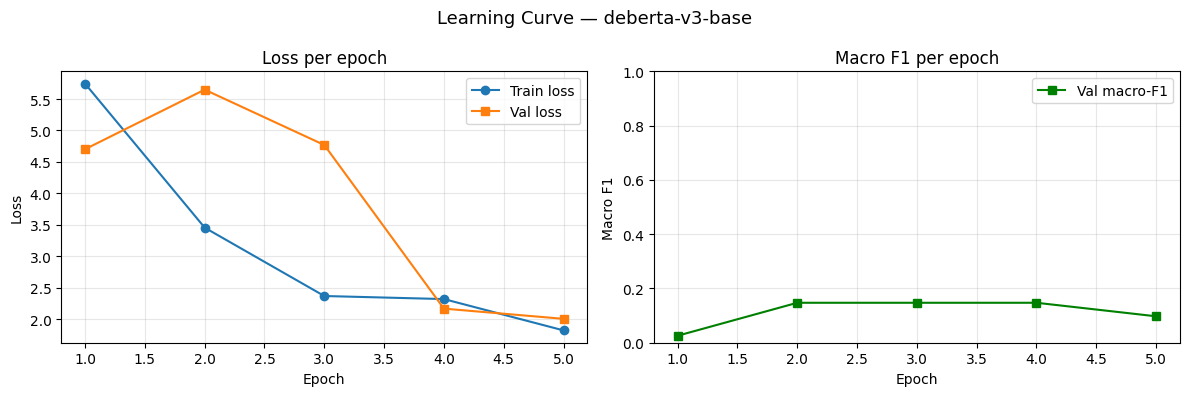

Saved: deberta-v3-base_learning_curve.png



=== deberta-v3-base — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.000     0.000     0.000       168
   Interpret      0.559     1.000     0.717      1131
      Reveal      0.000     0.000     0.000       670
      Revise      0.000     0.000     0.000        45
     Inquire      0.000     0.000     0.000         8

    accuracy                          0.559      2022
   macro avg      0.112     0.200     0.143      2022
weighted avg      0.313     0.559     0.401      2022


=== deberta-v3-base — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat               0             168            0            0   
true_Interpret              0            1131            0            0   
true_Reveal                 0             670            0            0   
true_Revise                 0              45            0            0   
true_Inquire                0  

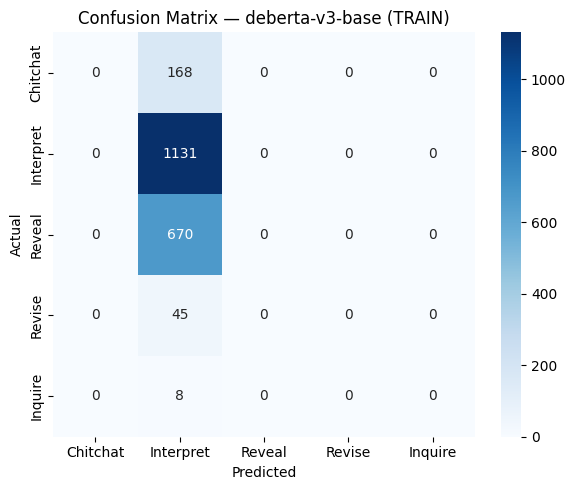


=== deberta-v3-base — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.000     0.000     0.000        36
   Interpret      0.582     1.000     0.736       304
      Reveal      0.000     0.000     0.000       168
      Revise      0.000     0.000     0.000        10
     Inquire      0.000     0.000     0.000         4

    accuracy                          0.582       522
   macro avg      0.116     0.200     0.147       522
weighted avg      0.339     0.582     0.429       522


=== deberta-v3-base — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat               0              36            0            0   
true_Interpret              0             304            0            0   
true_Reveal                 0             168            0            0   
true_Revise                 0              10            0            0   
true_Inquire                0      

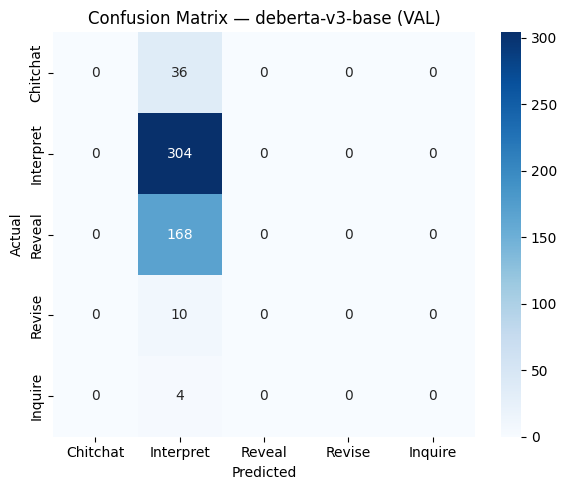


=== deberta-v3-base VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,168
1,Chitchat,Interpret,36
2,Revise,Interpret,10
3,Inquire,Interpret,4



=== deberta-v3-base VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
0,USER: hi!,Chitchat,Interpret
4,USER: I want to buy a bicycle,Reveal,Interpret
5,USER: I want to buy a bicycle\nSYSTEM: How abo...,Revise,Interpret
7,USER: I want Cotton socks,Reveal,Interpret
8,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Interpret
9,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Interpret
10,USER: I want to buy some acne treatment ointme...,Reveal,Interpret
12,"USER: I want some magic kits, or tutorials.",Reveal,Interpret
15,"USER: Show me some stylish, lightweight Compac...",Reveal,Interpret
17,USER: I want a Collapsible Water Bottle,Reveal,Interpret



=== TEST LABEL DISTRIBUTION ===
TRUE: {'Chitchat': 64, 'Interpret': 378, 'Reveal': 193, 'Revise': 12, 'Inquire': 5}
PREDICTED: {'Interpret': 652}
Prediction IDs present: [np.int64(1)]



=== deberta-v3-base — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.000     0.000     0.000        64
   Interpret      0.580     1.000     0.734       378
      Reveal      0.000     0.000     0.000       193
      Revise      0.000     0.000     0.000        12
     Inquire      0.000     0.000     0.000         5

    accuracy                          0.580       652
   macro avg      0.116     0.200     0.147       652
weighted avg      0.336     0.580     0.426       652


=== deberta-v3-base — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat               0              64            0            0   
true_Interpret              0             378            0            0   
true_Reveal                 0             193            0            0   
true_Revise                 0              12            0            0   
true_Inquire                0    

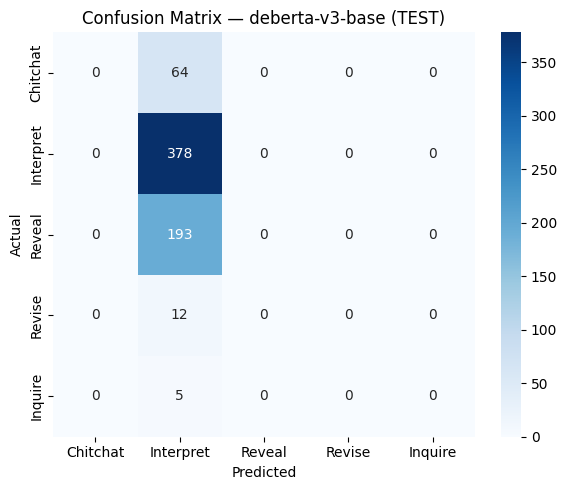


=== deberta-v3-base TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,193
1,Chitchat,Interpret,64
2,Revise,Interpret,12
3,Inquire,Interpret,5



=== deberta-v3-base TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
0,USER: I want a model airplane,Reveal,Interpret
1,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Interpret
2,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Interpret
3,USER: hi!,Chitchat,Interpret
4,USER: hi!\nSYSTEM: hi\nUSER: I wanna a bicycle!!,Reveal,Interpret
7,USER: I want to buy an electronic lock,Reveal,Interpret
9,USER: I want a cotton slippers.,Reveal,Interpret
10,USER: I want a cotton slippers.\nSYSTEM: do yo...,Reveal,Interpret
11,USER: I want a cotton slippers.\nSYSTEM: do yo...,Reveal,Interpret
12,USER: I want to buy a school bag,Reveal,Interpret


In [ ]:
deberta_trainer = run_model(
    "microsoft/deberta-v3-base",
    num_epochs=5,
    learning_rate=1e-5,
    use_class_weights=True,
)


MODEL: microsoft/deberta-v3-base
Learning rate: 1e-05
Epochs: 5
Class weighting: False


config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Best checkpoint: ./deberta-v3-base_results/checkpoint-253
Best validation macro-F1: 0.025806451612903226


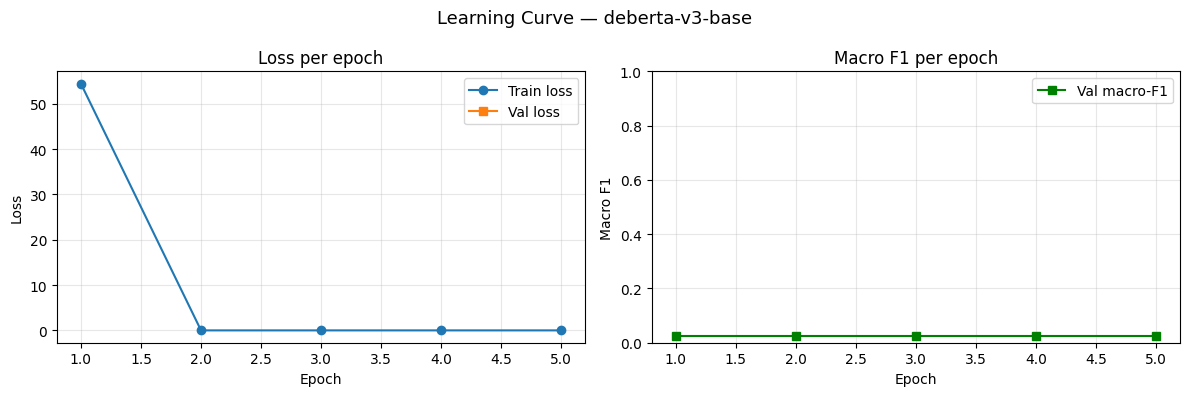

Saved: deberta-v3-base_learning_curve.png



=== deberta-v3-base — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.083     1.000     0.153       168
   Interpret      0.000     0.000     0.000      1131
      Reveal      0.000     0.000     0.000       670
      Revise      0.000     0.000     0.000        45
     Inquire      0.000     0.000     0.000         8

    accuracy                          0.083      2022
   macro avg      0.017     0.200     0.031      2022
weighted avg      0.007     0.083     0.013      2022


=== deberta-v3-base — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat             168               0            0            0   
true_Interpret           1131               0            0            0   
true_Reveal               670               0            0            0   
true_Revise                45               0            0            0   
true_Inquire                8  

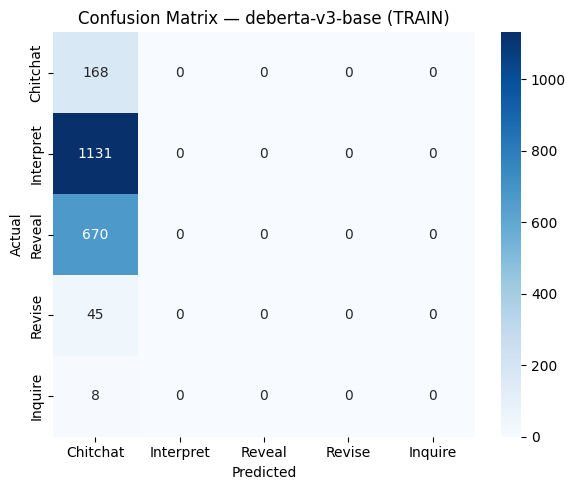


=== deberta-v3-base — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.069     1.000     0.129        36
   Interpret      0.000     0.000     0.000       304
      Reveal      0.000     0.000     0.000       168
      Revise      0.000     0.000     0.000        10
     Inquire      0.000     0.000     0.000         4

    accuracy                          0.069       522
   macro avg      0.014     0.200     0.026       522
weighted avg      0.005     0.069     0.009       522


=== deberta-v3-base — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat              36               0            0            0   
true_Interpret            304               0            0            0   
true_Reveal               168               0            0            0   
true_Revise                10               0            0            0   
true_Inquire                4      

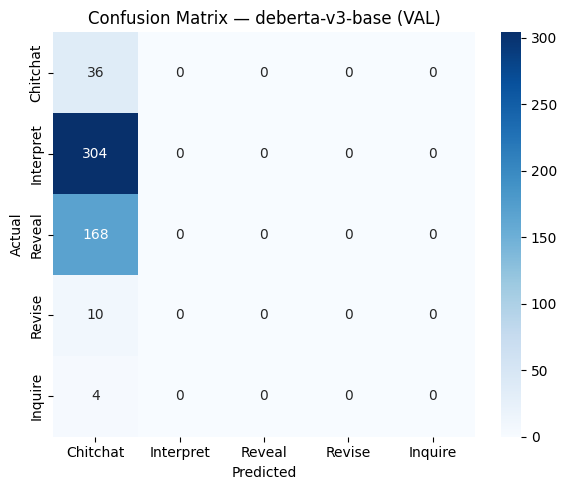


=== deberta-v3-base VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Interpret,Chitchat,304
1,Reveal,Chitchat,168
2,Revise,Chitchat,10
3,Inquire,Chitchat,4



=== deberta-v3-base VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a plane.,Interpret,Chitchat
2,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a pla...,Interpret,Chitchat
3,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a pla...,Interpret,Chitchat
4,USER: I want to buy a bicycle,Reveal,Chitchat
5,USER: I want to buy a bicycle\nSYSTEM: How abo...,Revise,Chitchat
6,USER: I want to buy a bicycle\nSYSTEM: How abo...,Interpret,Chitchat
7,USER: I want Cotton socks,Reveal,Chitchat
8,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Chitchat
9,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Chitchat
10,USER: I want to buy some acne treatment ointme...,Reveal,Chitchat



=== TEST LABEL DISTRIBUTION ===
TRUE: {'Chitchat': 64, 'Interpret': 378, 'Reveal': 193, 'Revise': 12, 'Inquire': 5}
PREDICTED: {'Chitchat': 652}
Prediction IDs present: [np.int64(0)]



=== deberta-v3-base — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.098     1.000     0.179        64
   Interpret      0.000     0.000     0.000       378
      Reveal      0.000     0.000     0.000       193
      Revise      0.000     0.000     0.000        12
     Inquire      0.000     0.000     0.000         5

    accuracy                          0.098       652
   macro avg      0.020     0.200     0.036       652
weighted avg      0.010     0.098     0.018       652


=== deberta-v3-base — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat              64               0            0            0   
true_Interpret            378               0            0            0   
true_Reveal               193               0            0            0   
true_Revise                12               0            0            0   
true_Inquire                5    

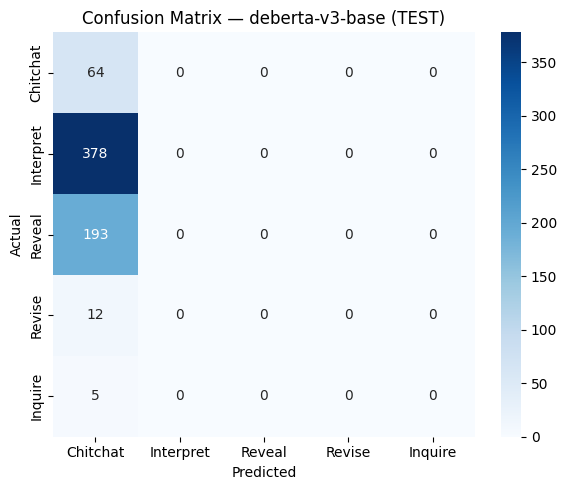


=== deberta-v3-base TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Interpret,Chitchat,378
1,Reveal,Chitchat,193
2,Revise,Chitchat,12
3,Inquire,Chitchat,5



=== deberta-v3-base TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
0,USER: I want a model airplane,Reveal,Chitchat
1,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Chitchat
2,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Chitchat
4,USER: hi!\nSYSTEM: hi\nUSER: I wanna a bicycle!!,Reveal,Chitchat
5,USER: hi!\nSYSTEM: hi\nUSER: I wanna a bicycle...,Interpret,Chitchat
6,USER: hi!\nSYSTEM: hi\nUSER: I wanna a bicycle...,Interpret,Chitchat
7,USER: I want to buy an electronic lock,Reveal,Chitchat
8,USER: I want to buy an electronic lock\nSYSTEM...,Interpret,Chitchat
9,USER: I want a cotton slippers.,Reveal,Chitchat
10,USER: I want a cotton slippers.\nSYSTEM: do yo...,Reveal,Chitchat


In [16]:
deberta_trainer = run_model(
    "microsoft/deberta-v3-base",
    num_epochs=5,
    learning_rate=1e-5,
    use_class_weights=False,
)

### What to inspect after the run

Record the **best validation Macro F1**, final **test Macro F1 / accuracy / weighted F1 / per-class F1**, and the printed **TEST predicted-label distribution**. If validation Macro F1 remains abnormally low, do not tune using the test result; the next diagnostic should compare a lower learning rate using validation performance.